---
title: "Practice Activity 9-1"
author: "Patrick Mori"

format:
  html:
    theme: minty
    toc: true
execute:
  echo: true
embed-resources: true

---


# K-Nearest Neighbors and Decision Trees for Regression

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

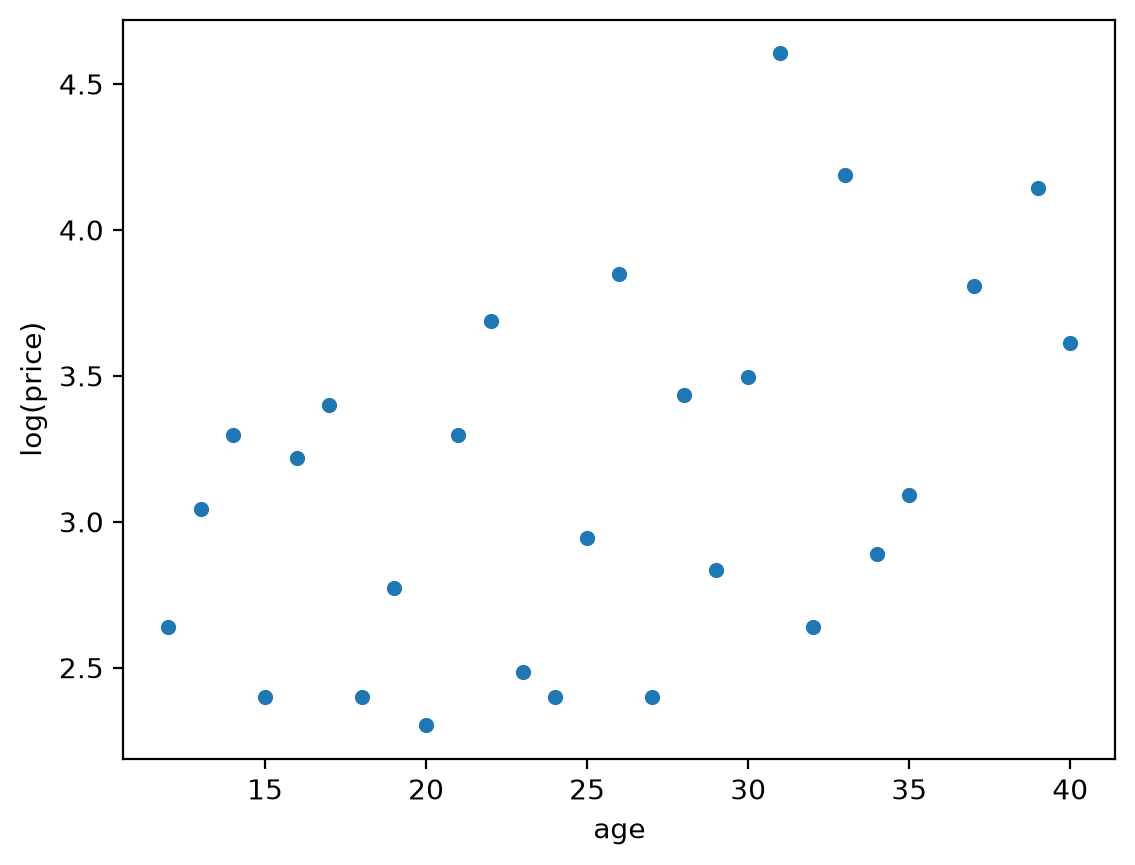

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

A 1-nearest-neighbor model predicts the log(price) of the closest training observation. The prediction stays constant until another observation becomes closer, so we should draw a step-shaped line that passes near each data point.

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

A 2-nearest-neighbor model predicts the average log(price) of the two closest observations. The predictions are less variable than with 1-NN, so we should draw a smoother step-shaped line.

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

Since the training set contains 27 observations, a 27-nearest-neighbor model uses every observation for every prediction. We should draw one horizontal line at the overall average log(price).

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

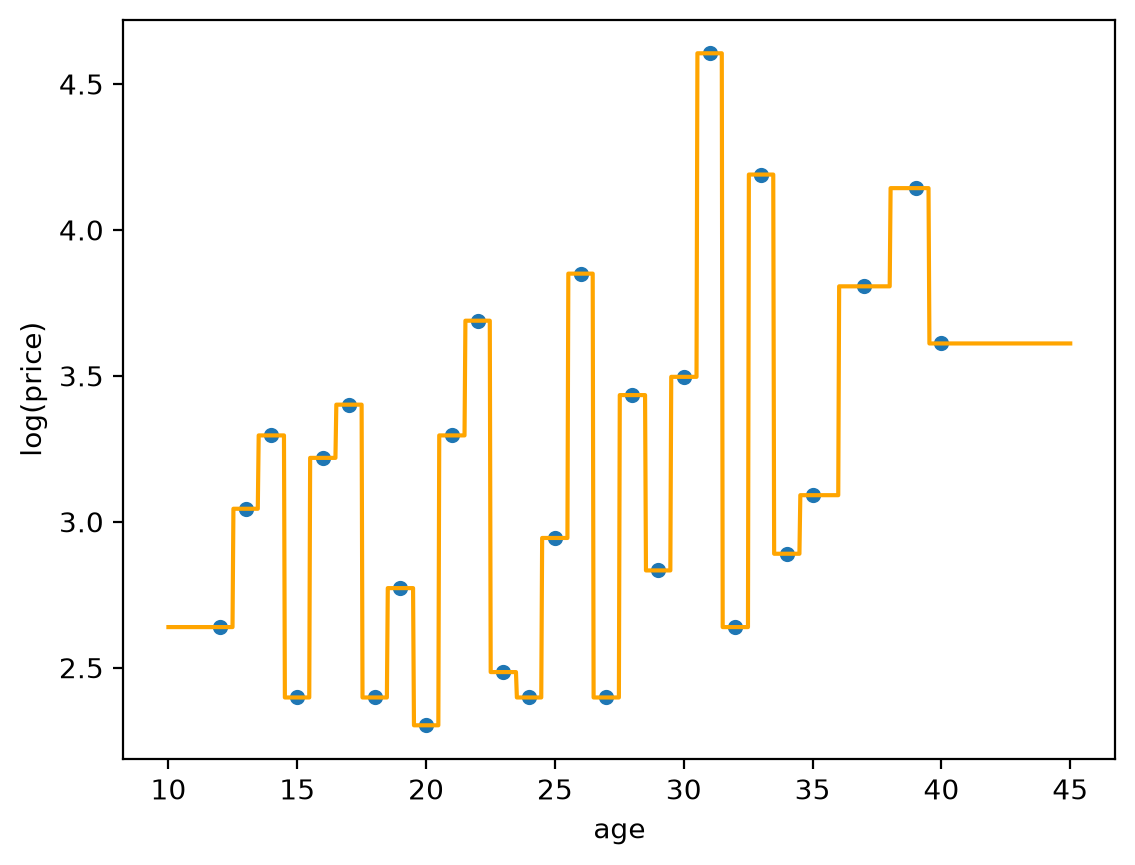

In [5]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


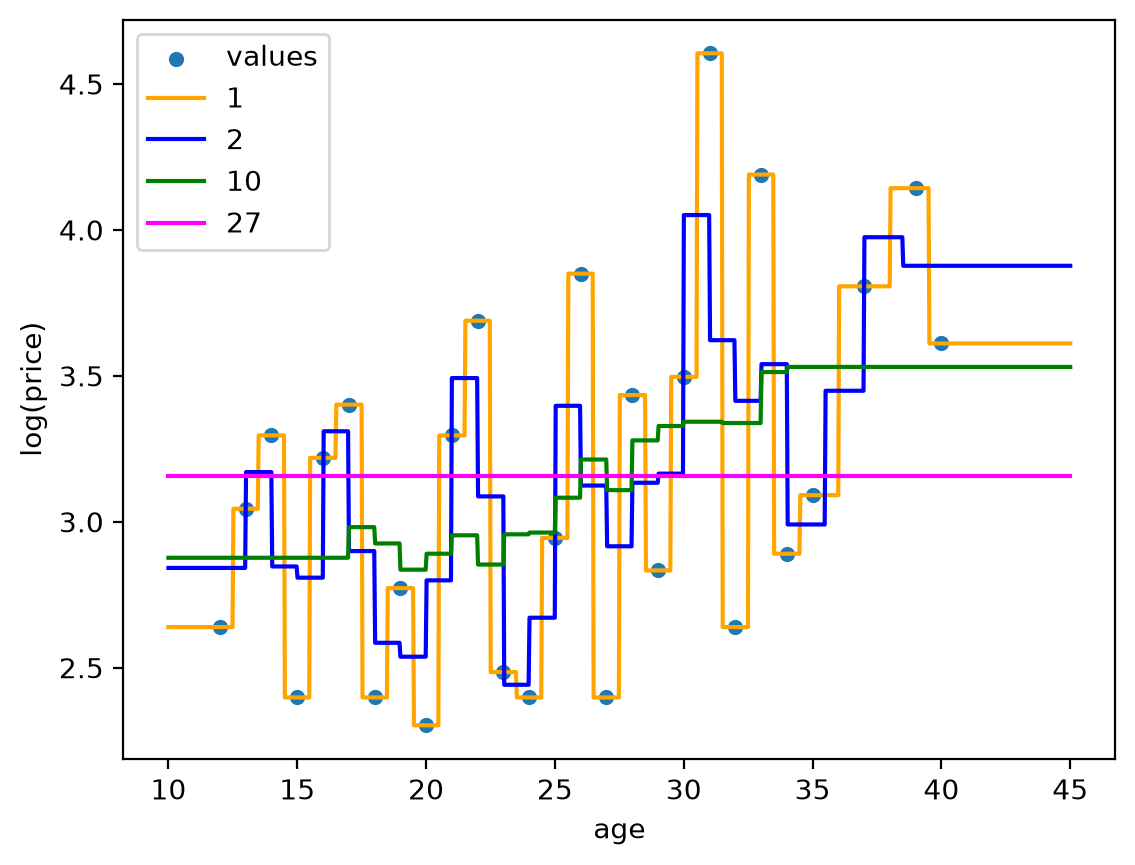

In [6]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


As \(k\) increases, the regression function becomes smoother and less affected by individual observations. The \(k=1\) model follows the data closely, while the \(k=27\) model is a constant horizontal line.

### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [7]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,ex

Now we'll find the predicted price for each Neighborhood.

In [9]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [10]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

Blueste has a predicted price equal to its neighborhood mean because it contains exactly 10 houses and the model uses 10 neighbors. Neighborhoods with more than 10 houses use only a subset of their houses, while neighborhoods with fewer than 10 houses must include houses from other neighborhoods.

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

With two observations, the feature space is divided into two regions based on which observation is closer. Each region predicts the target value of its nearest observation. We should draw two flat regions separated by a straight boundary.

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

With three observations, the feature space is divided into three nearest-neighbor regions. Each region predicts the target value of its nearest observation. We should draw three flat regions with boundaries between them.

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

With three observations and \(k=2\), each prediction is the average target value of the two closest observations. We should draw three possible flat regions, one for each possible pair of nearest observations.

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

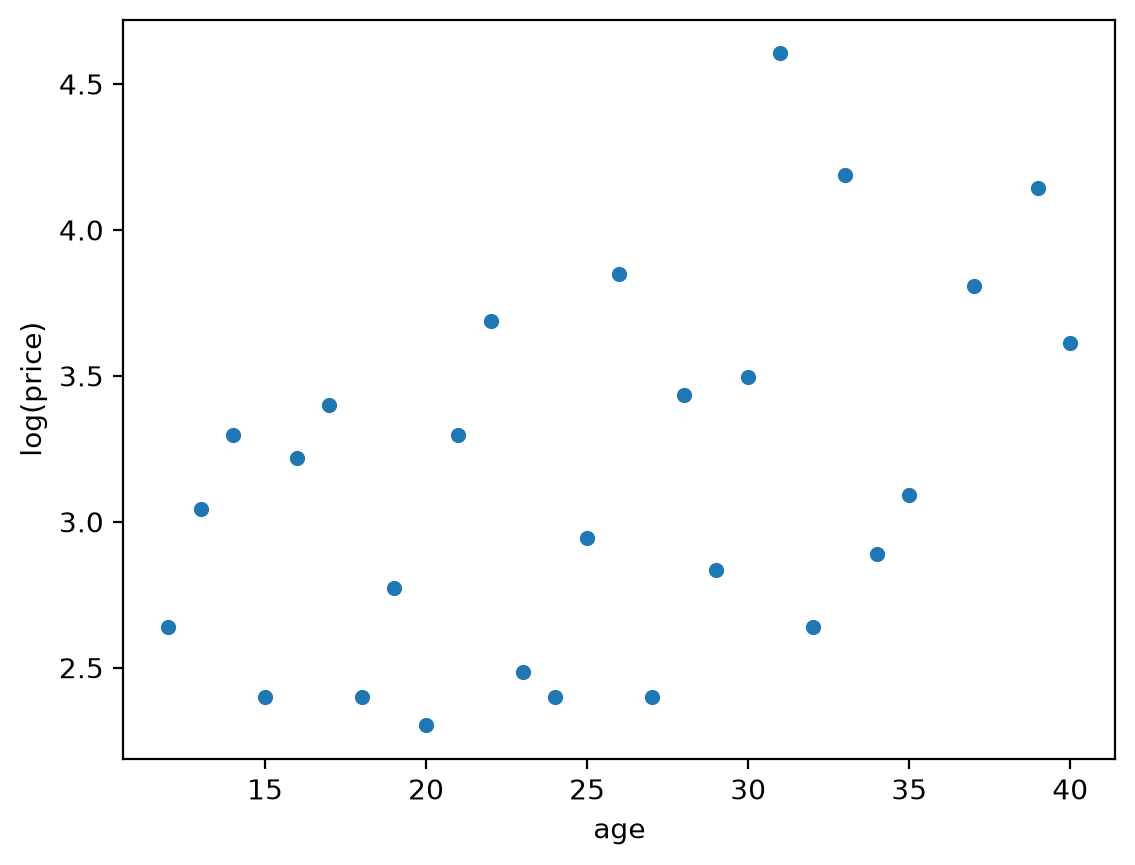

In [11]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

A decision tree with one split produces two constant predictions: one for younger wines and another for older wines. We should draw two horizontal sections with a jump at the split.

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

A decision tree with two splits produces three groups of wines, and each group receives its own average log(price). We should draw three horizontal sections with jumps at the two split points.

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

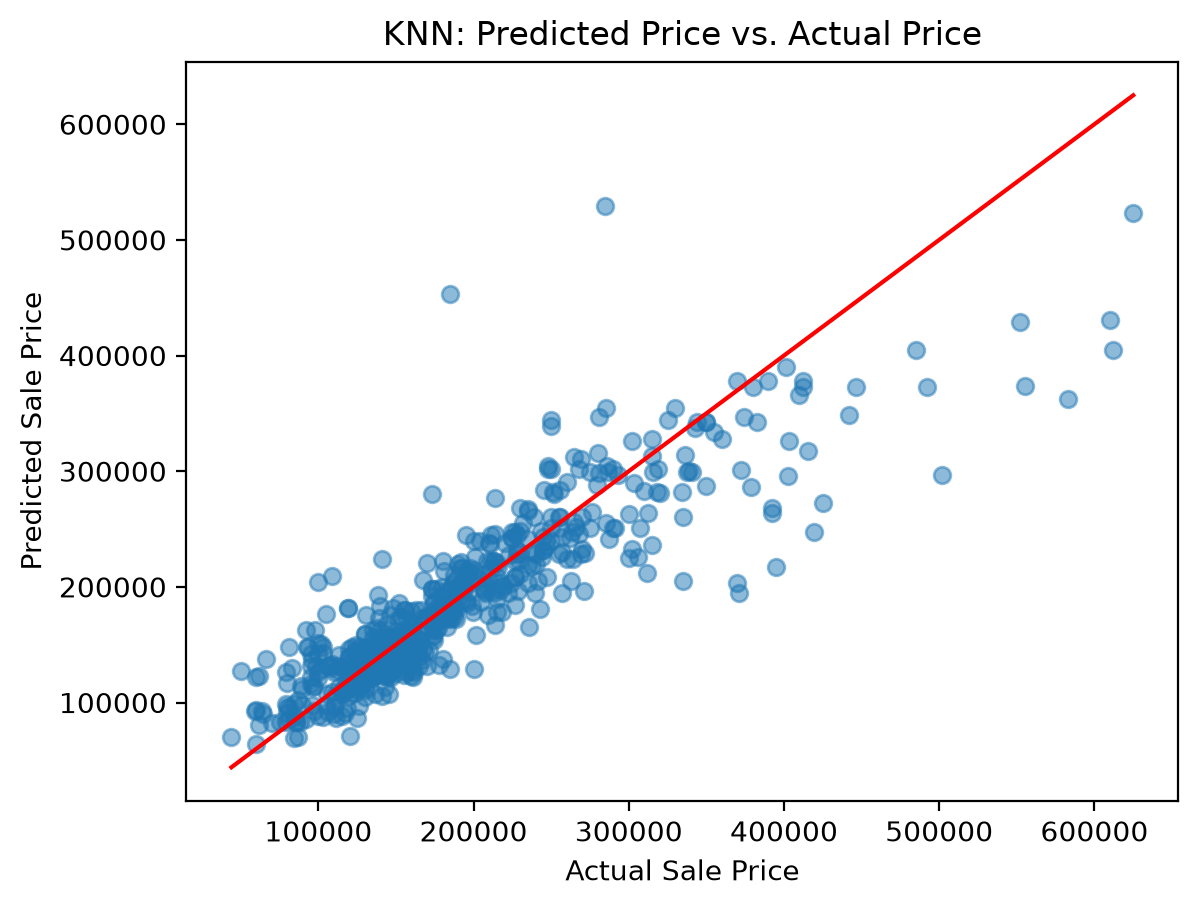

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt

# Select features and target
features = [
    "Gr Liv Area",
    "Bedroom AbvGr",
    "Full Bath",
    "Half Bath",
    "Neighborhood"
]

X = df_ames[features]
y = df_ames["SalePrice"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Scale quantitative features and dummify Neighborhood
preprocessor = ColumnTransformer([
    ("scale", StandardScaler(), [
        "Gr Liv Area",
        "Bedroom AbvGr",
        "Full Bath",
        "Half Bath"
    ]),
    ("dummify", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"])
])

# Create and fit the 10-nearest-neighbors model
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X_train, y_train)

# Predict the test data
y_pred = knn_model.predict(X_test)

# Plot predicted price versus actual price
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("KNN: Predicted Price vs. Actual Price")

# Add a reference line for perfect predictions
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], color="red")

plt.show()

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

In [13]:
from sklearn.metrics import mean_squared_error

# Try several values of k
k_values = [3, 5, 10, 15, 20]
results = []

for k in k_values:
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = mean_squared_error(y_test, predictions) ** 0.5
    results.append([k, rmse])

# Display the results
results_df = pd.DataFrame(results, columns=["k", "Test RMSE"])
print(results_df)

# Find the best k
best_row = results_df.loc[results_df["Test RMSE"].idxmin()]
print("Best k:", int(best_row["k"]))
print("Lowest test RMSE:", round(best_row["Test RMSE"], 2))

    k     Test RMSE
0   3  45160.976447
1   5  42439.371988
2  10  42561.508392
3  15  43651.687735
4  20  44679.028723
Best k: 5
Lowest test RMSE: 42439.37


I tested several values of \(k\). I selected the value with the lowest test RMSE because it produced predictions closest to the actual sale prices. According to the output, the best value was the one printed as “Best k.”

13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

In [15]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error

# Decision trees do not require quantitative features to be scaled
tree_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", [
        "Gr Liv Area",
        "Bedroom AbvGr",
        "Full Bath",
        "Half Bath"
    ]),
    ("neighborhood",
     OneHotEncoder(handle_unknown="ignore"),
     ["Neighborhood"])
])

# Create and fit the regression tree
tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("tree", DecisionTreeRegressor(max_depth=4, random_state=42))
])

tree_model.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_model.predict(X_test)

# Calculate test RMSE
tree_rmse = mean_squared_error(y_test, tree_predictions) ** 0.5
print("Test RMSE:", round(tree_rmse, 2))

Test RMSE: 55053.1


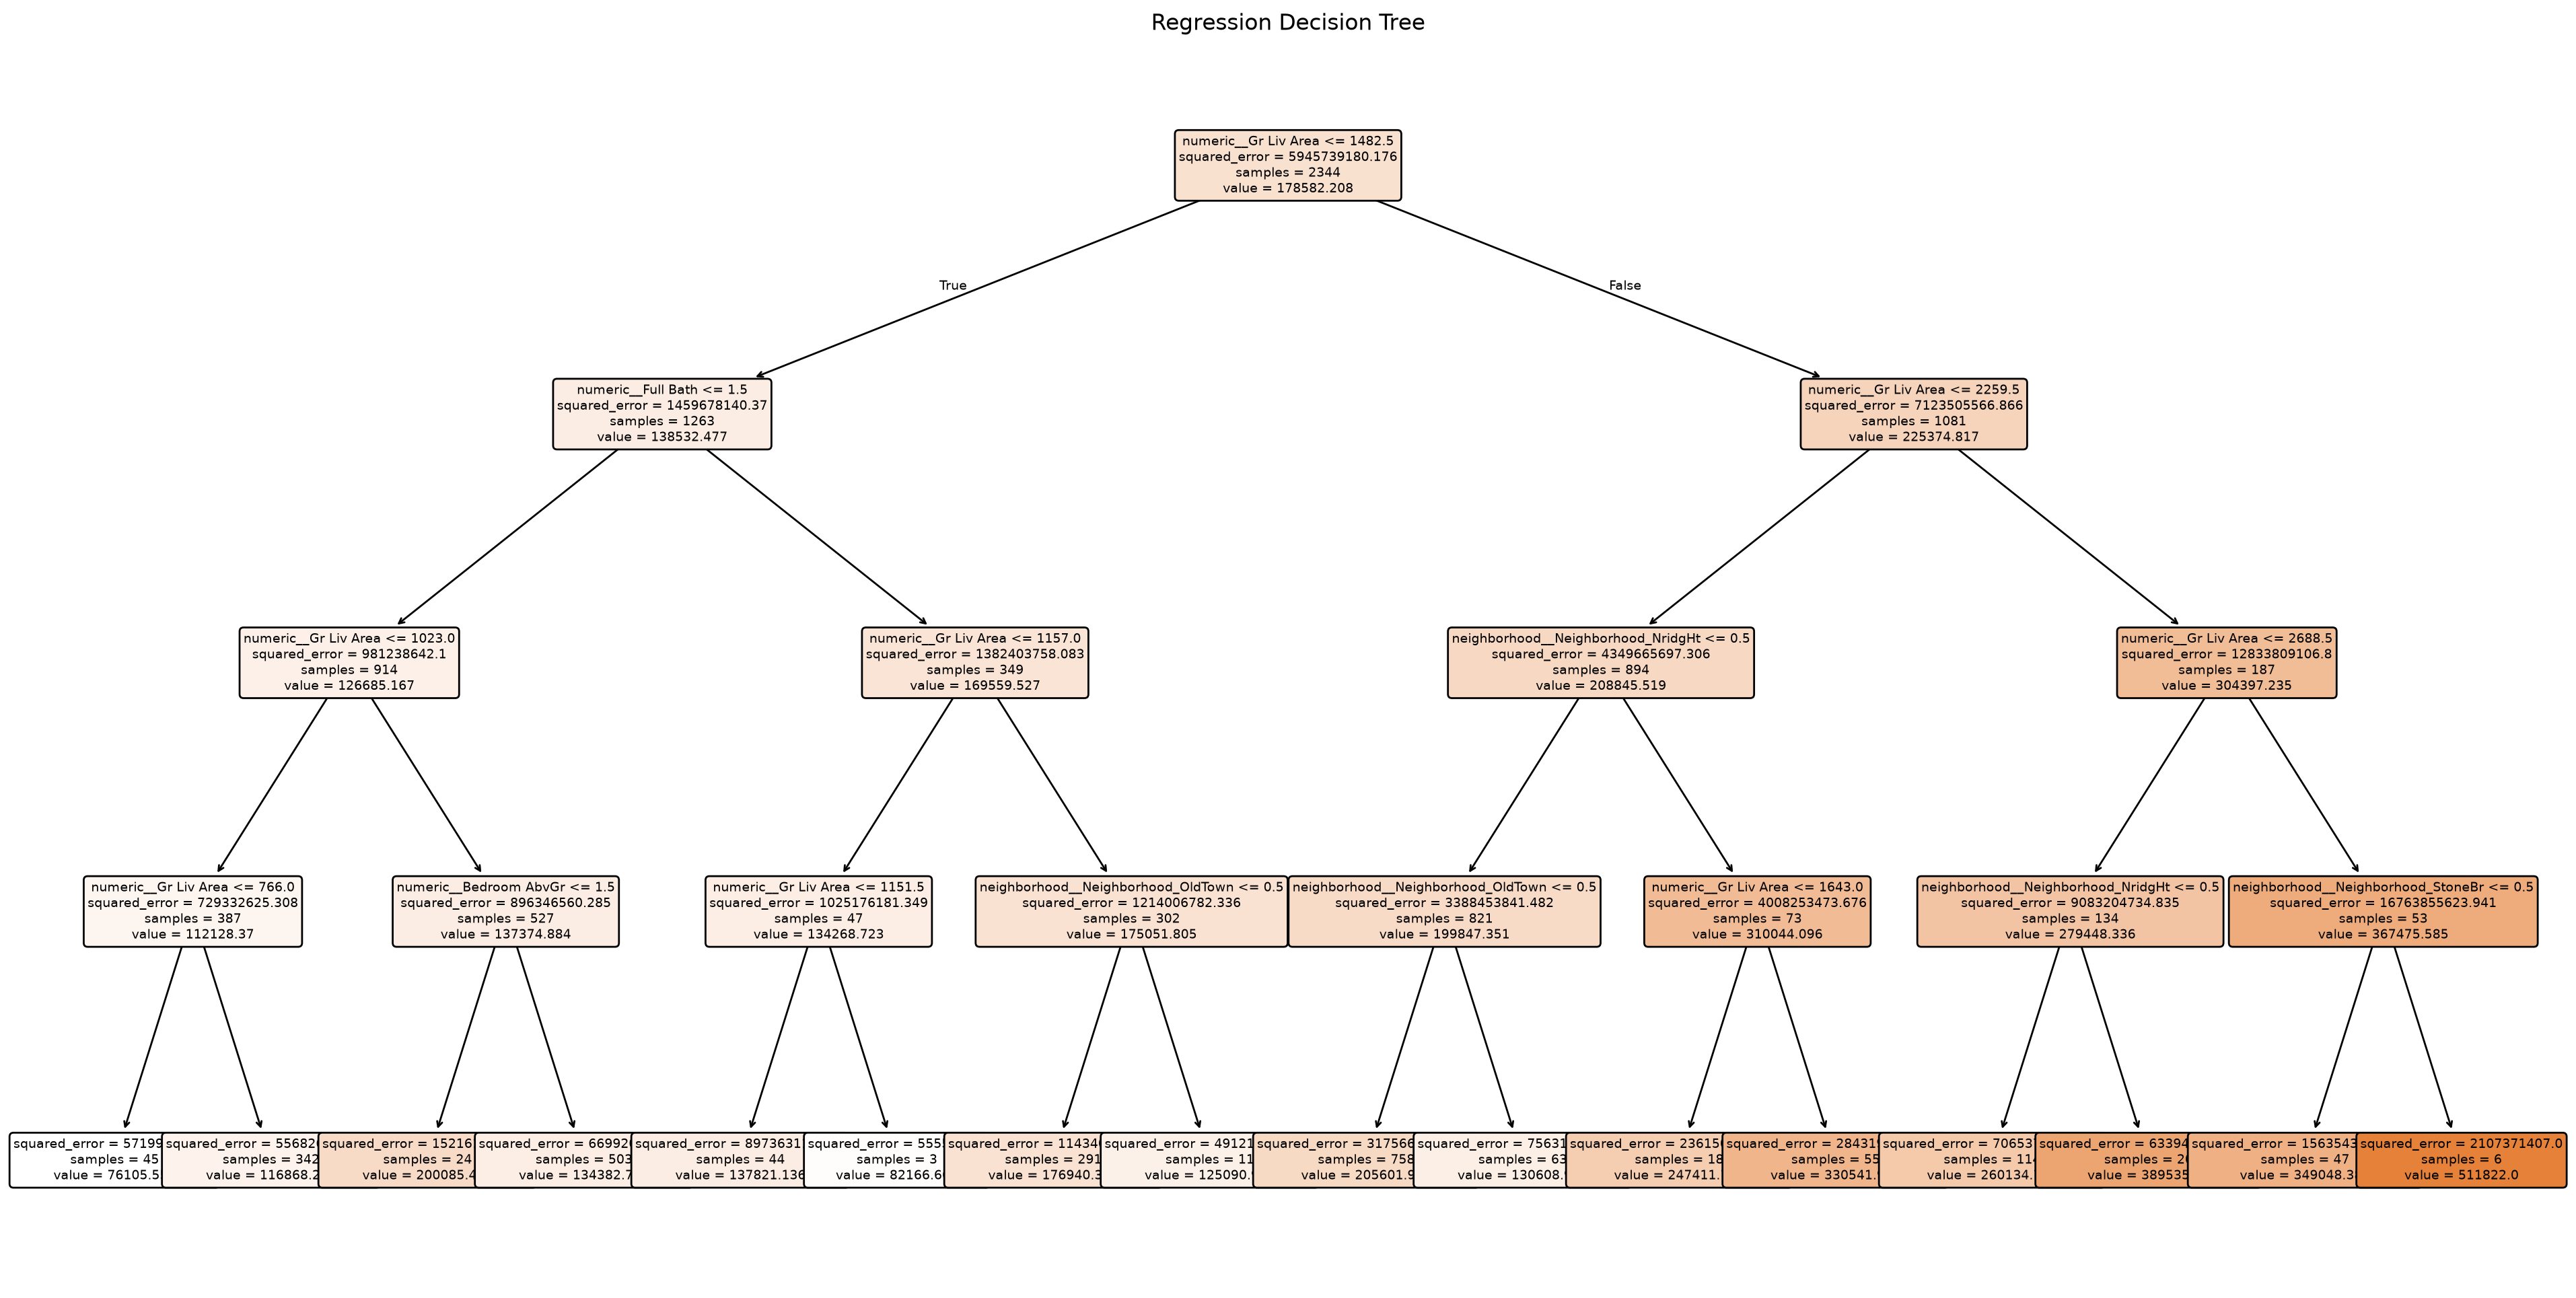

In [16]:
# Get the transformed feature names
feature_names = (
    tree_model.named_steps["preprocessing"].get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model.named_steps["tree"],
    feature_names=feature_names,
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Regression Decision Tree")
plt.show()

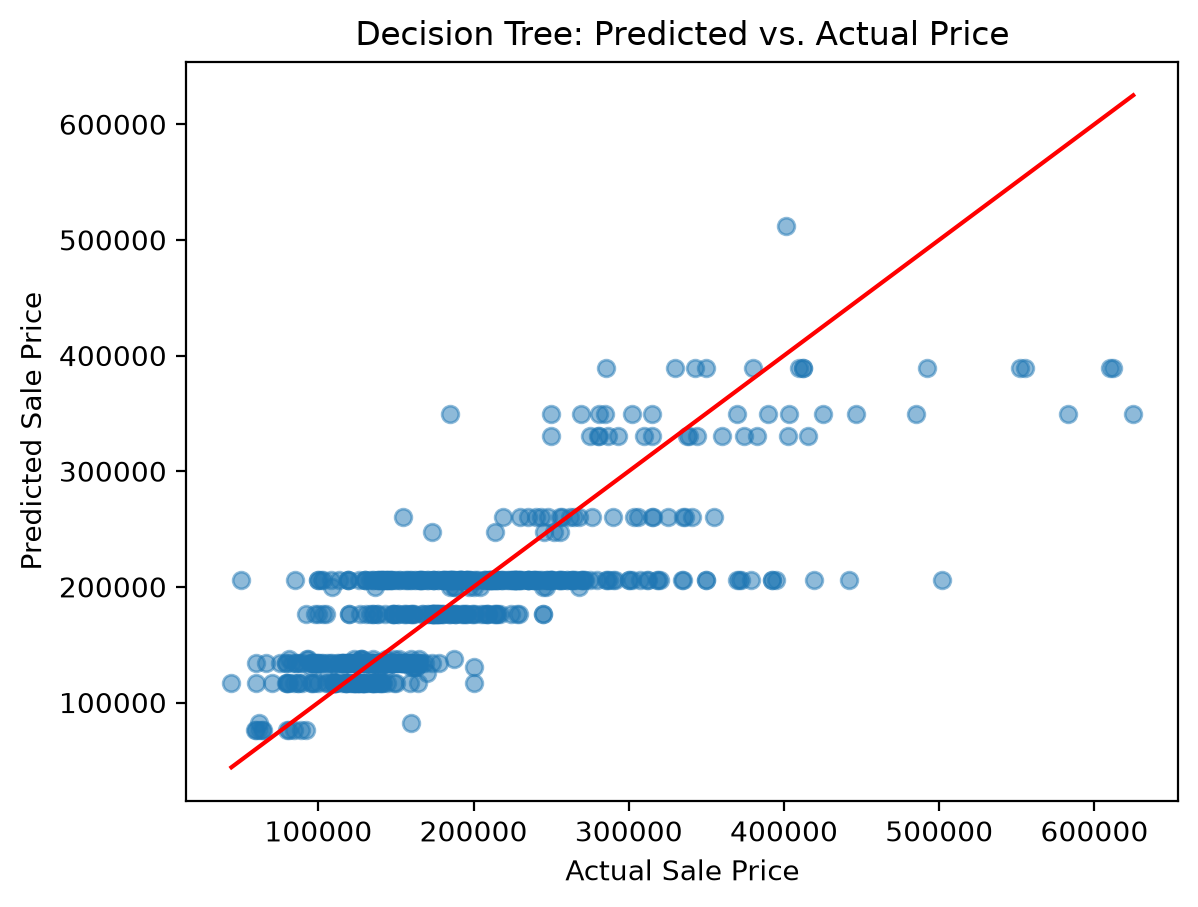

In [17]:
plt.scatter(y_test, tree_predictions, alpha=0.5)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Decision Tree: Predicted vs. Actual Price")

# Perfect-prediction reference line
low = min(y_test.min(), tree_predictions.min())
high = max(y_test.max(), tree_predictions.max())
plt.plot([low, high], [low, high], color="red")

plt.show()

The decision tree divides the houses into groups based on characteristics such as living area and neighborhood. Each final leaf predicts the average sale price of the houses in that group. In general, homes with more living area and homes in more expensive neighborhoods receive higher predicted prices. The red line in the scatterplot represents perfect predictions, so points closer to the line are more accurate.

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

In [18]:
# Try several maximum tree depths
depth_values = [2, 3, 4, 5, 6, 8, 10]
results = []

for depth in depth_values:
    model = Pipeline([
        ("preprocessing", tree_preprocessor),
        ("tree", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = mean_squared_error(y_test, predictions) ** 0.5
    results.append([depth, rmse])

# Display the results
depth_results = pd.DataFrame(
    results,
    columns=["Max Depth", "Test RMSE"]
)

print(depth_results)

# Find the best depth
best_row = depth_results.loc[depth_results["Test RMSE"].idxmin()]

print("Best max depth:", int(best_row["Max Depth"]))
print("Lowest test RMSE:", round(best_row["Test RMSE"], 2))

   Max Depth     Test RMSE
0          2  64225.037808
1          3  61394.543324
2          4  55053.101782
3          5  50890.653362
4          6  46117.967819
5          8  43936.633581
6         10  47136.269489
Best max depth: 8
Lowest test RMSE: 43936.63


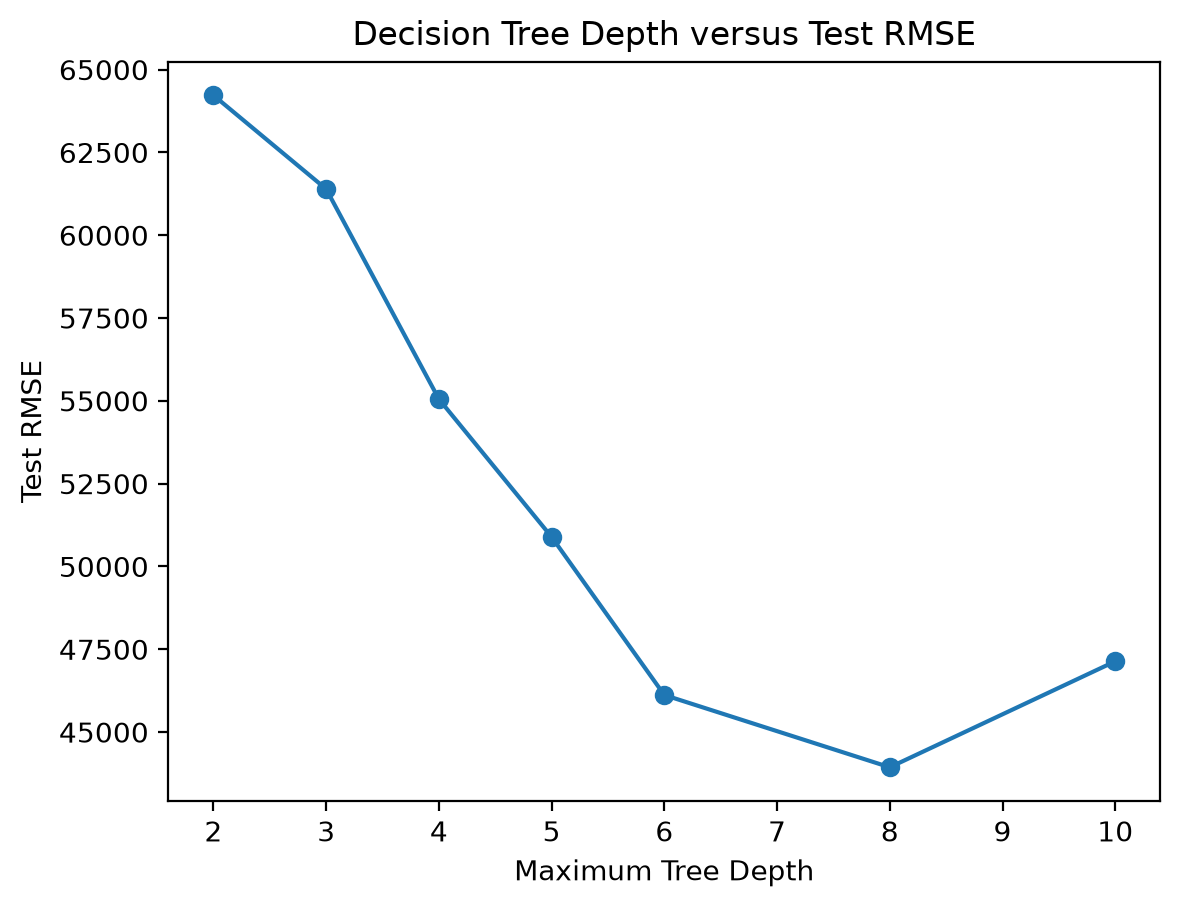

In [19]:
plt.plot(
    depth_results["Max Depth"],
    depth_results["Test RMSE"],
    marker="o"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Test RMSE")
plt.title("Decision Tree Depth versus Test RMSE")
plt.show()

I tested several values of max_depth and selected the depth with the lowest test RMSE. A tree that is too shallow may miss important patterns, while a tree that is too deep may overfit the training data. According to the output, the best value is the one printed as “Best max depth.”